---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 2"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 9. Нелінійні схеми на ОП: компаратори, тригери Шмітта, прецизійні випрямлячі</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>Додаткова тема (основа для питань 3.13–3.20): компаратори на ОП</li>
  <li>Тригери Шмітта (компаратори з гістерезисом)</li>
  <li>Прецизійні випрямлячі, піковий детектор, обмежувачі</li>
  <li>Логарифмічні та антилогарифмічні перетворювачі, пристрої вибірки-зберігання</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 9 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Вступ: ОП у нелінійному режимі](#intro)
* [Компаратори](#comparators)
* [Тригери Шмітта (компаратори з гістерезисом)](#schmitt)
    * [🔬 Інтерактивно: компаратор і тригер Шмітта на зашумленому сигналі (PySpice)](#schmitt-interactive)
* [Прецизійні випрямлячі, піковий детектор, обмежувачі](#rectifiers)
    * [🔬 Інтерактивно: звичайний і прецизійний випрямлячі, піковий детектор (PySpice)](#rect-interactive)
* [Логарифмічні та антилогарифмічні перетворювачі. Пристрої вибірки-зберігання](#log-amp)
    * [🔬 Інтерактивно: логарифмічний перетворювач (PySpice)](#log-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Вступ: ОП у нелінійному режимі <a class="anchor" id="intro"></a>

У темах 7–8 ОП завжди був охоплений **негативним** ЗЗ і працював на лінійній ділянці. Значна частина застосувань ОП — **нелінійні**:
- **без ЗЗ або з позитивним ЗЗ** ОП працює як **ключ**: вихід перебуває в одному з двох станів насичення $\pm U_{нас}$ (компаратори, тригери Шмітта, мультивібратори — теми 13–14);
- **з нелінійним елементом у колі ЗЗ** (діод, стабілітрон, транзистор) ОП «виправляє» недоліки цього елемента: прецизійні випрямлячі працюють з мілівольтовими сигналами, бо поріг діода ділиться на $K_0$; логарифмічні перетворювачі використовують експоненціальну характеристику p-n переходу.

Ця тема — додаткова: вона розширює огляд застосувань ОП і є основою для генераторів імпульсів (теми 13–14).

---

## Компаратори <a class="anchor" id="comparators"></a>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу компаратора на ОП і спеціалізованої мікросхеми компаратора
> - Будувати передавальні характеристики компаратора з опорною напругою і віконного компаратора
> - Пояснювати проблему брязкоту (багаторазового перемикання) на зашумленому сигналі

</div>

**Компаратор** порівнює вхідну напругу з опорною і видає логічний результат:
$$U_{вих} = \begin{cases} +U_{нас}, & U_{вх} > U_{оп},\\ -U_{нас}, & U_{вх} < U_{оп}\end{cases}\quad(\text{неінвертувальне ввімкнення}).$$
ОП без ЗЗ має $K_0 \sim 10^5$, тож зона невизначеності $\Delta U = 2U_{нас}/K_0$ — десятки мікровольт. **Компаратор нуля** — $U_{оп} = 0$ (детектор переходу через нуль); з дільником на одному з входів — **компаратор рівня**.

**ОП як компаратор має недоліки:** низька швидкість (вихід виходить із насичення, обмежений SR: μA741 перемикається за десятки мікросекунд), вихідні рівні не сумісні з логікою, вхідні кола деяких ОП не допускають великої диференціальної напруги. Тому використовують **спеціалізовані компаратори** (LM311, LM393, LM339, TLV3501): без частотної корекції, час перемикання — від наносекунд, вихід з відкритим колектором (потрібен резистор підтяжки до живлення логіки).

**Віконний компаратор** — два компаратори з порогами $U_н$ і $U_в$ та логічне «І» виходів: сигнал «норма», коли $U_н < U_{вх} < U_в$. Застосування — контроль напруги живлення, температури, допускового контролю.

**Брязкіт (дребезг).** Якщо вхідний сигнал повільно перетинає поріг і містить шум, вихід компаратора багаторазово перемикається біля порогу. Рішення — **гістерезис** (тригер Шмітта, наступний розділ).

**Застосування:** формувачі імпульсів із синусоїди, детектори переходу через нуль (синхронізація тиристорних регуляторів, вимірювання частоти й фази), контроль рівнів (зарядні пристрої, захист від перенапруги), АЦП (паралельний АЦП — $2^n - 1$ компаратор, АЦП послідовного наближення), ШІМ-модулятори (порівняння сигналу з пилкою).

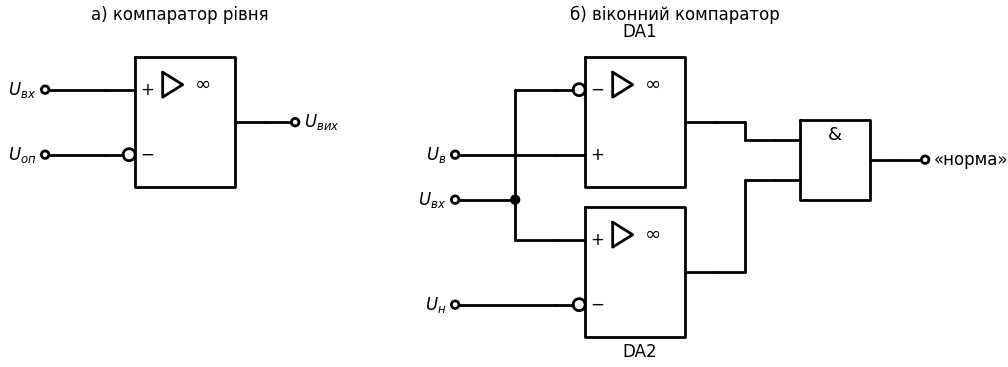

In [2]:
# а) компаратор з опорною напругою; б) віконний компаратор
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((2.6, 3.4)).label('а) компаратор рівня')
        d += (o := OpAmp(swap=True).at((1.2, 2)).anchor('in2'))
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left'); d += W((0, 2), (1.2, 2))
        d += elm.Dot(open=True).at((0, o.in1[1])).label('$U_{оп}$', loc='left'); d += W((0, o.in1[1]), o.in1)
        d += W(o.out, (5.0, o.out[1])); d += elm.Dot(open=True).at((5.0, o.out[1])).label('$U_{вих}$', loc='right')
        # б) віконний: DA1 видає «1» при U_вх < U_в, DA2 — при U_вх > U_н
        ox = 9
        d += elm.Label().at((ox + 3.5, 3.4)).label('б) віконний компаратор')
        d += (a := OpAmp().at((ox + 1.2, 2)).anchor('in1'))                 # «−» угорі: U_вх; «+»: U_в
        d += (b := OpAmp(swap=True).at((ox + 1.2, -1.0)).anchor('in2'))     # «+» угорі: U_вх; «−»: U_н
        d += elm.Label().at((a.center[0], a.center[1] + 1.7)).label('DA1'); d += elm.Label().at((b.center[0], b.center[1] - 1.7)).label('DA2')
        d += W((ox + 0.4, 2), (ox + 0.4, -1.0)); d += W((ox + 0.4, 2), a.in1); d += W((ox + 0.4, -1.0), b.in2)
        d += elm.Dot(open=True).at((ox - 0.8, -0.2)).label('$U_{вх}$', loc='left'); d += W((ox - 0.8, -0.2), (ox + 0.4, -0.2)); d += elm.Dot().at((ox + 0.4, -0.2))
        d += elm.Dot(open=True).at((ox - 0.8, a.in2[1])).label('$U_в$', loc='left'); d += W((ox - 0.8, a.in2[1]), a.in2)
        d += elm.Dot(open=True).at((ox - 0.8, b.in1[1])).label('$U_н$', loc='left'); d += W((ox - 0.8, b.in1[1]), b.in1)
        d += (g := Gate('&', 2, inv=False).at((ox + 5.6, 1.0)).anchor('in1'))
        d += W(a.out, (ox + 5.0, a.out[1])); d += W((ox + 5.0, a.out[1]), (ox + 5.0, g.in1[1])); d += W((ox + 5.0, g.in1[1]), g.in1)
        d += W(b.out, (ox + 5.0, b.out[1])); d += W((ox + 5.0, b.out[1]), (ox + 5.0, g.in2[1])); d += W((ox + 5.0, g.in2[1]), g.in2)
        d += W(g.out, (g.out[0] + 0.6, g.out[1])); d += elm.Dot(open=True).at((g.out[0] + 0.6, g.out[1])).label('«норма»', loc='right')

---

## Тригери Шмітта (компаратори з гістерезисом) <a class="anchor" id="schmitt"></a>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип дії тригера Шмітта і роль позитивного ЗЗ
> - Розраховувати пороги спрацьовування і ширину петлі гістерезису інвертувального і неінвертувального тригерів
> - Пояснювати, як гістерезис усуває брязкіт

</div>

**Тригер Шмітта** — компаратор, охоплений **позитивним ЗЗ** через подільник $R_1, R_2$. Поріг перемикання залежить від поточного стану виходу: при $U_{вих} = +U_{нас}$ він один, при $-U_{нас}$ — інший. Передавальна характеристика має **петлю гістерезису**.

### Інвертувальний тригер Шмітта

Сигнал — на інвертувальний вхід; подільник $R_1$ (до землі або $U_{оп}$), $R_2$ (від виходу) — на неінвертувальний. Коефіцієнт ПЗЗ $\gamma = \dfrac{R_1}{R_1 + R_2}$. Пороги (при $U_{оп} = 0$):
$$U_{пор}^{\pm} = \pm\gamma U_{нас} = \pm\frac{R_1}{R_1 + R_2}U_{нас},\qquad \Delta U_г = U_{пор}^+ - U_{пор}^- = \frac{2R_1}{R_1 + R_2}U_{нас}.$$
З опорною напругою на нижньому кінці $R_1$ петля зсувається: центр $U_{оп}\dfrac{R_2}{R_1 + R_2}$.

### Неінвертувальний тригер Шмітта

Сигнал через $R_1$ — на неінвертувальний вхід, $R_2$ — від виходу на той самий вхід, інвертувальний — на землі (або $U_{оп}$):
$$U_{пор}^{\pm} = \pm\frac{R_1}{R_2}U_{нас},\qquad \Delta U_г = \frac{2R_1}{R_2}U_{нас}.$$

**Чому зникає брязкіт:** після першого перемикання поріг «відскакує» на $\Delta U_г$ у протилежний бік; доки амплітуда шуму менша за $\Delta U_г$, повторних перемикань немає. ПЗЗ також **прискорює** перемикання (регенеративний процес). Обмеження розмаху виходу двома стабілітронами в колі виходу робить рівні стабільними.

**Застосування:** формувачі прямокутних імпульсів із зашумлених і повільних сигналів (вхідні кола мікроконтролерів, 74HC14), відновлення цифрових сигналів у лініях, двопозиційні регулятори (термостат: увімкнути при 19 °C, вимкнути при 21 °C), реле напруги, і головне — **основа релаксаційних генераторів** (мультивібратор = тригер Шмітта + RC-коло, тема 13).

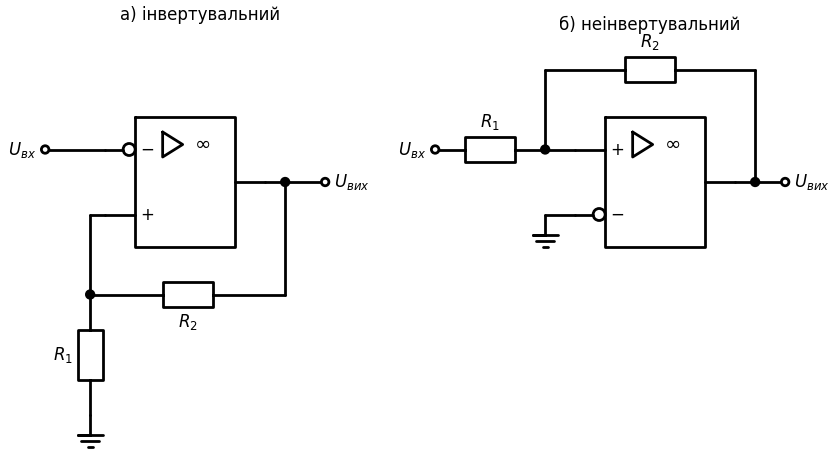

In [3]:
# а) інвертувальний; б) неінвертувальний тригер Шмітта
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((3.0, 4.6)).label('а) інвертувальний')
        d += (o := OpAmp().at((1.2, 2)).anchor('in1'))
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left'); d += W((0, 2), (1.2, 2))
        d += W(o.out, (5.6, o.out[1])); d += elm.Dot(open=True).at((5.6, o.out[1])).label('$U_{вих}$', loc='right'); d += elm.Dot().at((4.8, o.out[1]))
        d += W((4.8, o.out[1]), (4.8, -0.9)); d += elm.Resistor().at((4.8, -0.9)).to((0.9, -0.9)).label('$R_2$', loc='bottom')
        d += W((0.9, -0.9), (0.9, o.in2[1])); d += W((0.9, o.in2[1]), o.in2); d += elm.Dot().at((0.9, -0.9))
        d += elm.Resistor().at((0.9, -0.9)).to((0.9, -3.3)).label('$R_1$', loc='top'); d += elm.Ground().at((0.9, -3.3))
        ox = 9
        d += elm.Label().at((ox + 3.0, 4.6)).label('б) неінвертувальний')
        d += (o := OpAmp(swap=True).at((ox + 1.6, 2)).anchor('in2'))
        d += elm.Dot(open=True).at((ox - 1.2, 2)).label('$U_{вх}$', loc='left'); d += elm.Resistor().at((ox - 1.2, 2)).to((ox + 1.0, 2)).label('$R_1$')
        d += W((ox + 1.0, 2), (ox + 1.6, 2)); d += elm.Dot().at((ox + 1.0, 2))
        d += W((ox + 1.0, 2), (ox + 1.0, 3.6)); d += elm.Resistor().at((ox + 1.0, 3.6)).to((ox + 5.2, 3.6)).label('$R_2$')
        d += W((ox + 5.2, 3.6), (ox + 5.2, o.out[1])); d += W(o.out, (ox + 5.8, o.out[1])); d += elm.Dot().at((ox + 5.2, o.out[1]))
        d += elm.Dot(open=True).at((ox + 5.8, o.out[1])).label('$U_{вих}$', loc='right')
        d += W(o.in1, (ox + 1.0, o.in1[1])); d += elm.Ground().at((ox + 1.0, o.in1[1]))

---
### 🔬 Інтерактивно: компаратор і тригер Шмітта на зашумленому сигналі (PySpice) <a class="anchor" id="schmitt-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

На інвертувальний тригер Шмітта на μA741 (±15 В, $R_1$ — змінний, $R_2 = 100$ кОм) подано повільну синусоїду 100 Гц з шумом. При $R_1 = 0$ це звичайний компаратор нуля — біля кожного переходу через нуль він багаторазово перемикається. Збільшуйте $R_1$: щойно ширина петлі $\Delta U_г$ перевищить розмах шуму, брязкіт зникає. Праворуч — петля гістерезису $U_{вих}(U_{вх})$.

</div>

In [4]:
# Інвертувальний тригер Шмітта на μA741 із зашумленим входом
def schmitt(R1_k=5.0, noise_mV=150.0):
    rng = np.random.default_rng(1)
    tn = np.arange(0, 0.03, 20e-6)
    un = 1.0 * np.sin(2 * np.pi * 100 * tn) + noise_mV * 1e-3 * rng.standard_normal(len(tn))
    c = opamp_circuit('schmitt')
    c.PieceWiseLinearVoltageSource('in', 'in', c.gnd, values=list(zip(tn, un)))
    if R1_k > 0:
        c.R(1, 'p', c.gnd, R1_k * 1e3); c.R(2, 'out', 'p', 100e3)
    else:
        c.R(1, 'p', c.gnd, 1)
    add_opamp(c, 1, 'p', 'in', 'out')
    t, v = tran(c, 10e-6, 0.03)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2, 1]})
    a1.plot(t * 1e3, v['in'], color='#9E9E9E', lw=1, label='$u_{вх}$')
    a1.plot(t * 1e3, v['out'] / 10, color='#F44336', label='$u_{вих}$/10')
    g = R1_k / (R1_k + 100); Us = 14
    a1.axhline(g * Us, color='#2196F3', ls=':', lw=1); a1.axhline(-g * Us, color='#2196F3', ls=':', lw=1, label='пороги ±γU_нас')
    a1.set_xlabel('t, мс'); a1.set_ylabel('В'); a1.legend(loc='upper right', fontsize=9)
    edges = np.sum(np.abs(np.diff(np.sign(v['out']))) > 0)
    a1.set_title(f'$R_1$ = {R1_k:g} кОм: перемикань — {edges} (ідеально — 6)')
    a2.plot(v['in'], v['out'], color='#4CAF50', lw=1); a2.set_xlabel('$u_{вх}$, В'); a2.set_ylabel('$u_{вих}$, В'); a2.set_title('Петля гістерезису')
    plt.tight_layout(); plt.show()
    print(f'Ширина петлі ΔU_г = 2·R1/(R1+R2)·U_нас ≈ {2*g*Us*1e3:.0f} мВ;  розмах шуму ≈ ±{3*noise_mV:.0f} мВ (3σ)')

interact(schmitt,
         R1_k=widgets.FloatSlider(min=0, max=20, step=0.5, value=5, description='R1 (кОм)'),
         noise_mV=widgets.FloatSlider(min=0, max=300, step=10, value=150, description='σ шуму (мВ)'));

interactive(children=(FloatSlider(value=5.0, description='R1 (кОм)', max=20.0, step=0.5), FloatSlider(value=15…

---

## Прецизійні випрямлячі, піковий детектор, обмежувачі <a class="anchor" id="rectifiers"></a>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, чому звичайний діодний випрямляч непридатний для малих сигналів
> - Аналізувати однопівперіодний і двопівперіодний прецизійні випрямлячі
> - Пояснювати роботу активного пікового детектора та обмежувача на ОП

</div>

Діод починає проводити лише при $U > U_{пр} \approx 0{,}6$ В, тому сигнали з амплітудою в десятки–сотні мілівольт звичайним випрямлячем не випрямити. Якщо діод вмикнути **в петлю НЗЗ** ОП, ефективний поріг зменшується в $K_0$ разів: ОП автоматично піднімає свою вихідну напругу на $U_{пр}$, щоб відкрити діод — **«ідеальний діод»**.

### Однопівперіодний прецизійний випрямляч (інвертувальний)

Інвертувальний підсилювач з двома діодами: VD1 — у колі ЗЗ безпосередньо з виходу ОП на інвертувальний вхід, VD2 — послідовно з $R_2$ (вихідна точка $U_1$ — між VD2 і $R_2$).
- $U_{вх} < 0$: вихід ОП стає додатним, відкривається VD1 і замикає петлю на віртуальній землі, VD2 закритий, $U_1 = 0$;
- $U_{вх} > 0$: вихід ОП від'ємний, відкривається VD2, схема — інвертувальний підсилювач: $U_1 = -\frac{R_2}{R_1}U_{вх} < 0$.

Діод VD1 не дає ОП увійти в насичення на «неробочій» півхвилі, що підвищує швидкодію.

### Двопівперіодний прецизійний випрямляч (схема модуля)

До однопівперіодного випрямляча додають інвертувальний суматор, на який подається вхідний сигнал з вагою 1 і випрямлений — з вагою 2:
$$U_{вих} = -(U_{вх} + 2U_1) = |U_{вх}|\quad(\text{при } U_1 = -U_{вх}\text{ для } U_{вх} > 0,\;U_1 = 0\text{ для } U_{вх} < 0).$$
Застосування: вимірювачі середнього випрямленого значення (мультиметри змінного струму), АМ-детектори, вимірювачі рівня звуку, детектори огинаючої.

### Активний піковий детектор

ОП з діодом у петлі заряджає конденсатор $C$ до **пікового значення** вхідного сигналу (без втрати $U_{пр}$); вихідний повторювач запобігає розряду конденсатора навантаженням. Резистор розряду або ключ скидання задає час «забування». Застосування: вимірювачі пікових рівнів, АРП, спектрометрія імпульсів, детектори огинаючої.

### Обмежувачі

- **два стабілітрони** зустрічно-послідовно в колі ЗЗ інвертувального підсилювача: поки $|U_{вих}| < U_{ст} + U_{пр}$ — лінійне підсилення, далі вихід обмежується. Використовується для стабілізації рівнів компараторів і генераторів;
- **прецизійний обмежувач** — діод + опорна напруга в петлі ЗЗ.

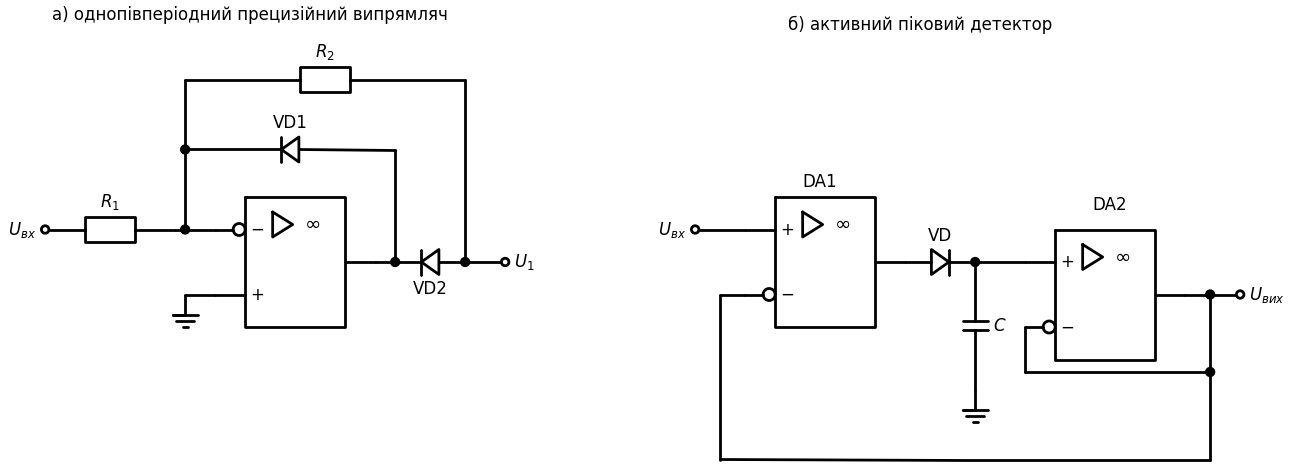

In [5]:
# а) однопівперіодний прецизійний випрямляч; б) активний піковий детектор
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += elm.Label().at((4.0, 6.2)).label('а) однопівперіодний прецизійний випрямляч')
        d += elm.Dot(open=True).at((0, 2)).label('$U_{вх}$', loc='left')
        d += elm.Resistor().at((0, 2)).to((2.6, 2)).label('$R_1$'); d += W((2.6, 2), (3.4, 2)); d += elm.Dot().at((2.8, 2))
        d += (o := OpAmp().at((3.4, 2)).anchor('in1'))
        d += W(o.out, (7.0, o.out[1])); d += elm.Dot().at((7.0, o.out[1]))
        d += W((7.0, o.out[1]), (7.0, 3.6)); d += elm.Diode().at((7.0, 3.6)).to((2.8, 3.6)).label('VD1')        # анод — вихід ОП
        d += W((2.8, 2), (2.8, 3.6)); d += elm.Dot().at((2.8, 3.6))
        d += W((2.8, 3.6), (2.8, 5.0)); d += elm.Resistor().at((2.8, 5.0)).to((8.4, 5.0)).label('$R_2$')
        d += elm.Diode().at((8.4, o.out[1])).to((7.0, o.out[1])).label('VD2', loc='bottom')                       # катод — вихід ОП
        d += W((8.4, 5.0), (8.4, o.out[1])); d += elm.Dot().at((8.4, o.out[1]))
        d += W((8.4, o.out[1]), (9.2, o.out[1])); d += elm.Dot(open=True).at((9.2, o.out[1])).label('$U_1$', loc='right')
        d += W(o.in2, (2.8, o.in2[1])); d += elm.Ground().at((2.8, o.in2[1]))
        # б) піковий детектор: DA1 + діод заряджають C, DA2 — повторювач; загальний ЗЗ з виходу DA2 на вхід DA1
        ox = 13
        d += elm.Label().at((ox + 4.6, 6.2)).label('б) активний піковий детектор')
        d += (a := OpAmp(swap=True).at((ox + 1.0, 2)).anchor('in2')); d += elm.Label().at((a.center[0], a.center[1] + 1.7)).label('DA1')
        d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left'); d += W((ox, 2), (ox + 1.0, 2))
        d += elm.Diode().at(a.out).to((ox + 5.6, a.out[1])).label('VD')
        d += elm.Dot().at((ox + 5.6, a.out[1])); d += elm.Capacitor().at((ox + 5.6, a.out[1])).to((ox + 5.6, -1.2)).label('$C$', loc='bottom'); d += elm.Ground().at((ox + 5.6, -1.2))
        d += (b := OpAmp(swap=True).at((ox + 6.6, a.out[1])).anchor('in2')); d += W((ox + 5.6, a.out[1]), b.in2)
        d += elm.Label().at((b.center[0], b.center[1] + 1.7)).label('DA2')
        xo = b.out[0] + 0.5; yl = b.in1[1] - 0.9
        d += W(b.out, (xo + 0.6, b.out[1])); d += elm.Dot().at((xo, b.out[1])); d += elm.Dot(open=True).at((xo + 0.6, b.out[1])).label('$U_{вих}$', loc='right')
        d += W(b.in1, (b.in1[0], yl)); d += W((b.in1[0], yl), (xo, yl)); d += W((xo, yl), (xo, b.out[1])); d += elm.Dot().at((xo, yl))
        d += W((xo, yl), (xo, -2.6)); d += W((xo, -2.6), (ox + 0.5, -2.6)); d += W((ox + 0.5, -2.6), (ox + 0.5, a.in1[1])); d += W((ox + 0.5, a.in1[1]), a.in1)

---
### 🔬 Інтерактивно: звичайний і прецизійний випрямлячі, піковий детектор (PySpice) <a class="anchor" id="rect-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Синусоїда 1 кГц малої амплітуди. Порівнюються: діодний однопівперіодний випрямляч (діод + резистор 10 кОм), прецизійний однопівперіодний (μA741, $R_1 = R_2 = 10$ кОм) і двопівперіодний прецизійний (з суматором). При амплітуді менше ≈0,5 В звичайний випрямляч не працює зовсім, прецизійний — випрямляє точно. Помітні сходинки при переході через нуль — обмежена швидкість наростання μA741 (ОП має «перестрибнути» на $2U_{пр}$).

</div>

In [6]:
# Діодний і прецизійні випрямлячі (PySpice, діоди 1N4148)
def rectifiers(Um=0.3, f_kHz=0.5):
    T = 1 / (f_kHz * 1e3)
    c = opamp_circuit('rectifiers')
    c.model('D4148', 'D', IS=2.52e-9, RS=0.568, N=1.752, CJO=4e-12, M=0.4, TT=20e-9, BV=100)
    c.SinusoidalVoltageSource('in', 'in', c.gnd, amplitude=Um, frequency=f_kHz * 1e3)
    c.D('s', 'in', 'simple', model='D4148'); c.R('s', 'simple', c.gnd, 10e3)               # звичайний випрямляч
    c.R(1, 'in', 'm', 10e3); add_opamp(c, 1, c.gnd, 'm', 'oa')                              # прецизійний однопівперіодний
    c.D(1, 'oa', 'm', model='D4148'); c.D(2, 'hw', 'oa', model='D4148'); c.R(2, 'hw', 'm', 10e3)
    c.R(3, 'in', 's2', 20e3); c.R(4, 'hw', 's2', 10e3); c.R(5, 's2', 'fw', 20e3)             # суматор: U_вих = −(U_вх + 2U_1) = |U_вх|
    add_opamp(c, 2, c.gnd, 's2', 'fw')
    t, v = tran(c, T / 400, 4 * T, start=2 * T)
    tt = (t - t[0]) * 1e3
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.plot(tt, v['in'], 'k--', lw=1, label='$u_{вх}$')
    ax.plot(tt, v['simple'], color='#9E9E9E', label='діодний випрямляч')
    ax.plot(tt, v['hw'], color='#2196F3', label='прецизійний однопівперіодний (інвертувальний)')
    ax.plot(tt, v['fw'], color='#F44336', label='прецизійний двопівперіодний $|u_{вх}|$')
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
    ax.set_title(f'Амплітуда {Um:g} В, частота {f_kHz:g} кГц')
    plt.tight_layout(); plt.show()

interact(rectifiers,
         Um=widgets.FloatSlider(min=0.05, max=3, step=0.05, value=0.3, description='Um (В)'),
         f_kHz=widgets.FloatLogSlider(base=10, min=-1, max=1, step=0.1, value=0.5, description='f (кГц)'));

interactive(children=(FloatSlider(value=0.3, description='Um (В)', max=3.0, min=0.05, step=0.05), FloatLogSlid…

---

## Логарифмічні та антилогарифмічні перетворювачі. Пристрої вибірки-зберігання <a class="anchor" id="log-amp"></a>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Виводити передавальну характеристику логарифмічного і антилогарифмічного перетворювачів
> - Пояснювати застосування логарифмування: стиснення динамічного діапазону, множення сигналів
> - Пояснювати принцип роботи пристрою вибірки-зберігання

</div>

### Логарифмічний перетворювач

Струм p-n переходу (діода або транзистора в діодному ввімкненні) експоненціально залежить від напруги: $I = I_S\left(e^{U/\varphi_т} - 1\right) \approx I_Se^{U/\varphi_т}$. Якщо ввімкнути перехід (діод або транзистор з заземленою базою, колектором до інвертувального входу) в коло ЗЗ інвертувального підсилювача, струм $U_{вх}/R$ проходить через нього, а вихідна напруга дорівнює $-U_{бе}$:
$$U_{вих} = -\varphi_т\ln\frac{U_{вх}}{RI_S} \approx -0{,}06\lg\frac{U_{вх}}{RI_S}\;\text{В}\quad(\text{−60 мВ на декаду}).$$
Схема працює лише для $U_{вх} > 0$; діапазон — до 5…7 декад. Сильна температурна залежність ($\varphi_т$ і $I_S$) компенсується другим, ідентичним транзистором і термозалежним резистором (інтегральні лог-підсилювачі LOG112, AD8304).

### Антилогарифмічний (експоненціальний) перетворювач

Транзистор і резистор міняють місцями (перехід — на вході, резистор — у ЗЗ):
$$U_{вих} = -RI_Se^{U_{вх}/\varphi_т}.$$

**Аналогові обчислення на логарифмах:** $\ln(xy) = \ln x + \ln y$, $\;\ln(x/y) = \ln x - \ln y$, $\;\ln x^n = n\ln x$ — множення, ділення, піднесення до степеня і корені виконуються суматорами між лог- і антилог-перетворювачами. Застосування: **стиснення динамічного діапазону** (вимірювачі в децибелах, фотометри, оптичні приймачі з динамічним діапазоном 120 дБ), RSSI-детектори в радіоприймачах, аналогові перемножувачі, вимірювачі середньоквадратичного значення.

### Пристрій вибірки-зберігання (ПВЗ, sample & hold)

Ключ (польовий транзистор) і конденсатор $C_з$ між двома повторювачами на ОП. У режимі **вибірки** ключ замкнений і напруга на $C_з$ відстежує вхідну; у режимі **зберігання** ключ розімкнений і вихід утримує останнє значення (вихідний повторювач з ПТ-входом практично не розряджає $C_з$). Параметри: час встановлення (вибірки), швидкість спаду в режимі зберігання $dU/dt = I_{вит}/C_з$, апертурна затримка. ПВЗ стоїть на вході АЦП — фіксує значення сигналу на час перетворення.

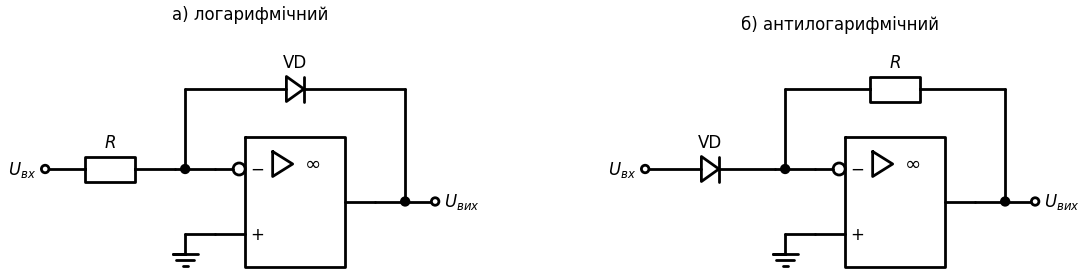

In [7]:
# а) логарифмічний перетворювач (p-n перехід у колі ЗЗ); б) антилогарифмічний (p-n перехід на вході)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        for ox, title, log in ((0, 'а) логарифмічний', True), (12, 'б) антилогарифмічний', False)):
            d += elm.Label().at((ox + 4.0, 5.0)).label(title)
            d += elm.Dot(open=True).at((ox, 2)).label('$U_{вх}$', loc='left')
            d += (o := OpAmp().at((ox + 3.4, 2)).anchor('in1'))
            d += elm.Dot().at((ox + 2.8, 2)); d += W((ox + 2.6, 2), (ox + 3.4, 2))
            (ci, li), (cf, lf) = ((elm.Resistor, '$R$'), (elm.Diode, 'VD')) if log else ((elm.Diode, 'VD'), (elm.Resistor, '$R$'))
            d += ci().at((ox, 2)).to((ox + 2.6, 2)).label(li)
            d += W((ox + 2.8, 2), (ox + 2.8, 3.6)); d += cf().at((ox + 2.8, 3.6)).to((ox + 7.2, 3.6)).label(lf)
            d += W((ox + 7.2, 3.6), (ox + 7.2, o.out[1])); d += elm.Dot().at((ox + 7.2, o.out[1]))
            d += W(o.out, (ox + 7.8, o.out[1])); d += elm.Dot(open=True).at((ox + 7.8, o.out[1])).label('$U_{вих}$', loc='right')
            d += W(o.in2, (ox + 2.8, o.in2[1])); d += elm.Ground().at((ox + 2.8, o.in2[1]))

---
### 🔬 Інтерактивно: логарифмічний перетворювач (PySpice) <a class="anchor" id="log-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Логарифмічний перетворювач на μA741 з транзистором 2N3904 (база заземлена, колектор — до інвертувального входу) і $R = 10$ кОм. Вхідна напруга змінюється від 1 мВ до 10 В (4 декади). На лінійній ділянці вихід змінюється на ≈ −60 мВ на декаду. Змінюйте температуру: нахил $\varphi_т\ln10$ пропорційний абсолютній температурі, а $I_S$ різко зростає — тому без термокомпенсації лог-підсилювач неточний.

</div>

In [8]:
# Логарифмічний перетворювач: DC-розгортка вхідної напруги
def log_amp(temp=25.0):
    c = opamp_circuit('log amp')
    c.include(spice_model('2n3904.lib'))
    c.V('in', 'in', c.gnd, 1.0)
    c.R(1, 'in', 'm', 10e3)
    c.BJT(1, 'm', c.gnd, 'out', model='Q2N3904')        # колектор — віртуальна земля, база — земля, емітер — вихід
    c.C(1, 'm', 'out', 100e-12)                          # корекція стійкості петлі
    add_opamp(c, 1, c.gnd, 'm', 'out')
    uin = np.logspace(-3, 1, 41); uout = []
    for u in uin:
        c['Vin'].dc_value = u
        op = c.simulator(temperature=temp, nominal_temperature=25).operating_point()
        uout.append(float(np.array(op['out'])[0]))
    uout = np.array(uout)
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.semilogx(uin, uout, 'o-', color='#F44336', ms=4, label=f'T = {temp:.0f} °C')
    slope = np.polyfit(np.log10(uin[8:33]), uout[8:33], 1)[0]
    ax.set_xlabel('$U_{вх}$, В'); ax.set_ylabel('$U_{вих}$, В'); ax.legend()
    ax.set_title(f'Логарифмічний перетворювач: нахил {slope*1e3:.1f} мВ/декаду (теорія −φт·ln10 = {-8.617e-5*(temp+273.15)*np.log(10)*1e3:.1f})')
    plt.tight_layout(); plt.show()

interact(log_amp, temp=widgets.FloatSlider(min=-20, max=80, step=5, value=25, description='T (°C)'));

interactive(children=(FloatSlider(value=25.0, description='T (°C)', max=80.0, min=-20.0, step=5.0), Output()),…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Компаратор на ОП ≠ спеціалізований компаратор.** ОП оптимізовано для роботи з НЗЗ: він має частотну корекцію (повільний) і довго виходить із насичення. У швидких схемах (ШІМ, формувачі з частотою > 10 кГц) використовують компаратори (LM393, LM311, TLV3201) — без корекції, з відкритим колектором і часом перемикання від наносекунд. І навпаки: компаратор не можна вмикати з НЗЗ як підсилювач — він самозбуджується.

</div>

---
### ⚡ Практичне застосування: нелінійні схеми на ОП

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Пристрій | Схема |
|---|---|
| Вхід мікроконтролера для зашумленого сигналу, кнопки | тригер Шмітта (74HC14 або на компараторі) |
| Термостат, зарядний пристрій | компаратор з гістерезисом і опорною напругою |
| Детектор переходу через нуль мережі (диммери) | компаратор нуля з гістерезисом |
| ШІМ-контролер, клас D | компаратор сигналу з пилкою |
| Мультиметр змінного струму (середнє випрямлене) | двопівперіодний прецизійний випрямляч + ФНЧ |
| АРП, вимірювач піків звуку | піковий детектор |
| Оптичний приймач з великим динамічним діапазоном, RSSI | логарифмічний перетворювач |
| Вхід АЦП | пристрій вибірки-зберігання |
| Генератори прямокутних і трикутних імпульсів | тригер Шмітта + інтегратор (тема 13) |

</div>

---
### ✅ Питання для самоперевірки: нелінійні схеми на ОП

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому компаратор без гістерезису «брязкотить» на зашумленому сигналі?</summary>

> **Відповідь:** Біля порогу шум багаторазово перетинає рівень порівняння, і кожен перетин перемикає дуже чутливий вихід.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Як розрахувати пороги інвертувального тригера Шмітта?</summary>

> **Відповідь:** $U_{пор}^{\pm} = \pm\frac{R_1}{R_1+R_2}U_{нас}$; ширина петлі $\Delta U_г = \frac{2R_1}{R_1+R_2}U_{нас}$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому прецизійний випрямляч працює з мілівольтовими сигналами?</summary>

> **Відповідь:** Діод у петлі НЗЗ: ОП автоматично підвищує вихідну напругу на $U_{пр}$, і ефективний поріг зменшується в $K_0$ разів.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Навіщо в піковому детекторі вихідний повторювач?</summary>

> **Відповідь:** Щоб навантаження не розряджало конденсатор; а загальний ЗЗ з виходу повторювача компенсує падіння напруги на діоді.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Чому логарифмічний перетворювач має -60 мВ на декаду?</summary>

> **Відповідь:** $U_{вих} = -\varphi_т\ln(U_{вх}/RI_S)$, і зміна в 10 разів дає $\varphi_т\ln10 \approx 26\cdot2{,}3 = 60$ мВ.

</details>

---
### 📝 Задачі для самостійного розв'язання: нелінійні схеми на ОП


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Інвертувальний тригер Шмітта: $U_{нас} = \pm12$ В, $R_2 = 100$ кОм. Яким має бути $R_1$ для петлі гістерезису шириною 0,5 В? Де будуть пороги при $U_{оп} = 2$ В на нижньому кінці $R_1$?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $2R_1\cdot12/(R_1 + 100\,\text{к}) = 0{,}5 \Rightarrow R_1 \approx 2{,}13$ кОм; центр петлі $2\cdot100/102{,}1 \approx 1{,}96$ В, пороги ≈ 2,21 В і 1,71 В.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Сигнал з амплітудою 50 мВ треба перетворити на модуль. Чому діодний випрямляч непридатний і що вийде на прецизійному двопівперіодному з одиничним коефіцієнтом?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> Діод відкривається лише при ≈0,6 В — сигнал 50 мВ не пройде. Прецизійний дасть $|u_{вх}|$ з амплітудою 50 мВ (середнє випрямлене $2\cdot50/\pi \approx 31{,}8$ мВ).

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Лог-перетворювач: $R = 10$ кОм, $I_S = 10^{-14}$ А, 25 °C. Знайдіть $U_{вих}$ при $U_{вх}$ = 10 мВ і 1 В.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $U_{вих} = -0{,}0257\ln(U_{вх}/(10^4\cdot10^{-14}))$: при 10 мВ $\approx -0{,}53$ В; при 1 В $\approx -0{,}65$ В (різниця 2 декади ≈ 118 мВ).

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Схема | Співвідношення |
|---|---|
| Компаратор | $U_{вих} = \pm U_{нас}$ залежно від знаку $U_{вх} - U_{оп}$ |
| Інвертувальний тригер Шмітта | $U_{пор}^\pm = \pm\frac{R_1}{R_1+R_2}U_{нас}$ |
| Неінвертувальний тригер Шмітта | $U_{пор}^\pm = \pm\frac{R_1}{R_2}U_{нас}$ |
| Прецизійний випрямляч | поріг $U_{пр}/K_0$; модуль: $U_{вих} = -(U_{вх} + 2U_1) = |U_{вх}|$ |
| Логарифмічний перетворювач | $U_{вих} = -\varphi_т\ln\frac{U_{вх}}{RI_S}$ (−60 мВ/дек) |
| Антилогарифмічний | $U_{вих} = -RI_Se^{U_{вх}/\varphi_т}$ |

**Головні висновки.** Без ЗЗ або з позитивним ЗЗ ОП працює як ключ (компаратор, тригер Шмітта), а з нелінійним елементом у колі НЗЗ — як прецизійний нелінійний перетворювач, що компенсує недоліки діодів. Тригер Шмітта з RC-колом стає генератором прямокутних імпульсів — саме з цього починаються мультивібратори (тема 13).

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Franco S. Design with Operational Amplifiers and Analog Integrated Circuits. — 4th ed. — McGraw-Hill, 2015 (розділи 9, 13).
7. Analog Devices. Nonlinear Circuits Handbook / Sheingold D. H. (ed.). — 1976.

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 8. Інтегратори, диференціатори, вимірювальні підсилювачі, перетворювачі U→I та I→U](Тема_08_Лінійні_перетворювачі_на_ОП.ipynb) &nbsp;|&nbsp; [Тема 10. Активні фільтри: класифікація, поліноми, елементарні ланки](Тема_10_Активні_фільтри_основи.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*